<a href="https://colab.research.google.com/github/denizbutengineer/bart-capacity-planner/blob/main/btk_final_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Ortam Kurulumu ve Ham Veri Yükleme
Gerekli kütüphaneleri kurar ve BART'ın 2025 yılına ait saatlik Başlangıç-Varış (Origin-Destination) ham yolcu verisini sıkıştırılmış .zip arşivinden bellek dostu veri tipleriyle okur.

In [1]:
!pip install -q lightgbm xgboost catboost holidays networkx joblib

import os
import glob
import joblib
import holidays
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

# Çalışma dizinindeki .zip veya .csv dosyasını otomatik bul
zip_files = glob.glob("*2025*.zip")
csv_files = glob.glob("*2025*.csv")

if zip_files:
    FILE_PATH = zip_files[0]
    COMPRESSION = "zip"
elif csv_files:
    FILE_PATH = csv_files[0]
    COMPRESSION = None
else:
    raise FileNotFoundError("Lütfen 'date-hour-soo-dest-2025.csv.zip' dosyasını Colab sol menüdeki 'Dosyalar' sekmesine yükleyin.")

print(f"Okunan dosya: {FILE_PATH} (Sıkıştırma: {COMPRESSION})")

cols = ['Date', 'Hour', 'Origin', 'Destination', 'Trips']
df_raw = pd.read_csv(
    FILE_PATH,
    compression=COMPRESSION,
    names=cols,
    dtype={'Hour': 'int8', 'Origin': 'category', 'Destination': 'category', 'Trips': 'int32'}
)
df_raw['Date'] = pd.to_datetime(df_raw['Date'])

print(f"Yüklenen toplam satır sayısı: {len(df_raw):,}")
display(df_raw.head())

Okunan dosya: date-hour-soo-dest-2025.zip (Sıkıştırma: zip)
Yüklenen toplam satır sayısı: 9,143,257


,Date,Hour,Origin,Destination,Trips
0,2025-01-01,0,12TH,16TH,1
1,2025-01-01,0,12TH,ANTC,1
2,2025-01-01,0,12TH,BALB,1
3,2025-01-01,0,12TH,BERY,1
4,2025-01-01,0,12TH,CIVC,8


# 2. Ağ Yönlendirme ve Hat Maksimum Kesit Yükü Hesaplama
İstasyon ağını graf olarak modeller, ortak koridorlardaki yolcu akışını o kesiti paylaşan hat sayısına böler ve her tarih, saat, hat ve yön için en kalabalık kesitteki yolcu yükünü (Max_Segment_Load) hesaplar

In [2]:
import gc

LINES = {
    'Red': [
        'RICH', 'DELN', 'PLZA', 'NBRK', 'DBRK', 'ASHB', 'MCAR', '19TH', '12TH', 'WOAK',
        'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY', 'COLM',
        'SSAN', 'SBRN', 'SFIA', 'MLBR'
    ],
    'Orange': [
        'RICH', 'DELN', 'PLZA', 'NBRK', 'DBRK', 'ASHB', 'MCAR', '19TH', '12TH', 'LAKE',
        'FTVL', 'COLS', 'SANL', 'BAYF', 'HAYW', 'SHAY', 'UCTY', 'FRMT', 'WARM', 'MLPT', 'BERY'
    ],
    'Yellow': [
        'ANTC', 'PCTR', 'PITT', 'NCON', 'CONC', 'PHIL', 'WCRK', 'LAFY', 'ORIN', 'ROCK',
        'MCAR', '19TH', '12TH', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH',
        'GLEN', 'BALB', 'DALY', 'COLM', 'SSAN', 'SBRN', 'SFIA'
    ],
    'Blue': [
        'DUBL', 'WDUB', 'CAST', 'BAYF', 'SANL', 'COLS', 'FTVL', 'LAKE', 'WOAK',
        'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY'
    ],
    'Green': [
        'BERY', 'MLPT', 'WARM', 'FRMT', 'UCTY', 'SHAY', 'HAYW', 'BAYF', 'SANL', 'COLS',
        'FTVL', 'LAKE', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY'
    ]
}

G = nx.DiGraph()
edge_to_lines = {}
all_edges = []

for line_name, stations in LINES.items():
    for i in range(len(stations) - 1):
        u, v = stations[i], stations[i + 1]
        G.add_edge(u, v)
        edge_to_lines.setdefault((u, v), []).append((line_name, 0))
    rev_stations = stations[::-1]
    for i in range(len(rev_stations) - 1):
        u, v = rev_stations[i], rev_stations[i + 1]
        G.add_edge(u, v)
        edge_to_lines.setdefault((u, v), []).append((line_name, 1))

# Kenarlara (U, V) benzersiz tam sayı Edge_ID ata (Bellek tasarrufu için)
edge_list = sorted(edge_to_lines.keys())
edge_to_id = {edge: idx for idx, edge in enumerate(edge_list)}

valid_stations = set(G.nodes())
od_pairs = df_raw[['Origin', 'Destination']].drop_duplicates()
od_pairs = od_pairs[
    od_pairs['Origin'].isin(valid_stations) &
    od_pairs['Destination'].isin(valid_stations) &
    (od_pairs['Origin'] != od_pairs['Destination'])
]

# Sadece (Origin, Destination, Edge_ID) eşleşmesi kur (Hat bazlı çoğaltmayı sonra yapacağız)
od_edge_rows = []
for row in od_pairs.itertuples(index=False):
    try:
        path = nx.shortest_path(G, row.Origin, row.Destination)
        for i in range(len(path) - 1):
            eid = edge_to_id[(path[i], path[i + 1])]
            od_edge_rows.append((row.Origin, row.Destination, eid))
    except nx.NetworkXNoPath:
        continue

df_od_edges = pd.DataFrame(od_edge_rows, columns=['Origin', 'Destination', 'Edge_ID'])
df_od_edges['Origin'] = df_od_edges['Origin'].astype(df_raw['Origin'].dtype)
df_od_edges['Destination'] = df_od_edges['Destination'].astype(df_raw['Destination'].dtype)
df_od_edges['Edge_ID'] = df_od_edges['Edge_ID'].astype('int16')

# RAM dostu: Ay bazında parçalayarak Edge_ID bazlı toplam yükleri hesapla
df_raw['Month_Tmp'] = df_raw['Date'].dt.month
edge_load_chunks = []

for m in range(1, 13):
    sub = df_raw[df_raw['Month_Tmp'] == m][['Date', 'Hour', 'Origin', 'Destination', 'Trips']]
    if sub.empty:
        continue
    merged = sub.merge(df_od_edges, on=['Origin', 'Destination'], how='inner')
    agg = merged.groupby(['Date', 'Hour', 'Edge_ID'], as_index=False)['Trips'].sum()
    edge_load_chunks.append(agg)
    del sub, merged
    gc.collect()

df_raw.drop(columns=['Month_Tmp'], inplace=True)
df_edge_totals = pd.concat(edge_load_chunks, ignore_index=True)
del edge_load_chunks
gc.collect()

# Şimdi küçük boyutlu df_edge_totals tablosunu hatlara dağıt
edge_line_map = []
for edge, serving in edge_to_lines.items():
    eid = edge_to_id[edge]
    share = 1.0 / len(serving)
    for line_name, direction in serving:
        edge_line_map.append((eid, line_name, direction, share))

df_edge_line = pd.DataFrame(edge_line_map, columns=['Edge_ID', 'Line', 'Direction', 'Share'])
df_edge_line['Edge_ID'] = df_edge_line['Edge_ID'].astype('int16')

df_line_loads = df_edge_totals.merge(df_edge_line, on='Edge_ID', how='inner')
df_line_loads['Edge_Load'] = (df_line_loads['Trips'] * df_line_loads['Share']).astype('float32')

hourly_max = (
    df_line_loads.groupby(['Date', 'Hour', 'Line', 'Direction'], as_index=False)['Edge_Load']
    .max()
    .rename(columns={'Edge_Load': 'Hourly_Max_Load'})
)

del df_edge_totals, df_line_loads
gc.collect()

print(f"Saatlik maksimum kesit yükü tablosu RAM dostu şekilde oluşturuldu: {len(hourly_max):,} satır")

Saatlik maksimum kesit yükü tablosu RAM dostu şekilde oluşturuldu: 81,325 satır


# 3. Keşifçi Veri Analizi (EDA) ve Veri Kalitesi Kontrolü
Sefer dışı boş saatleri takvim ızgarasıyla tamamlar, tekrarlayan kayıt (duplicate) kontrolü yapar ve hedef değişkenin hat ve saat bazlı dağılımını görselleştirir.

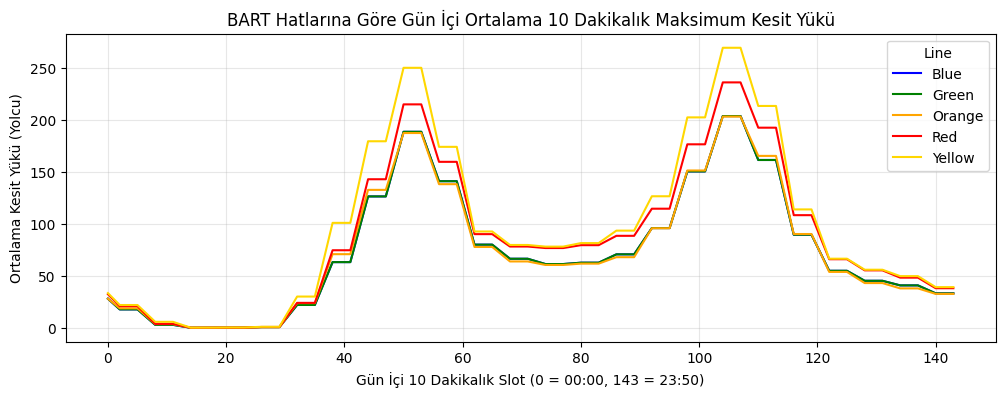

In [3]:
all_dates = pd.date_range(hourly_max['Date'].min(), hourly_max['Date'].max(), freq='D')
grid = pd.MultiIndex.from_product(
    [all_dates, range(24), list(LINES.keys()), [0, 1]],
    names=['Date', 'Hour', 'Line', 'Direction']
).to_frame(index=False)

df_hourly = grid.merge(hourly_max, on=['Date', 'Hour', 'Line', 'Direction'], how='left')
df_hourly['Hourly_Max_Load'] = df_hourly['Hourly_Max_Load'].fillna(0.0)

slots = pd.DataFrame({'Sub_Slot': range(6)})
df_full = df_hourly.merge(slots, how='cross')
df_full['Slot_Of_Day'] = (df_full['Hour'] * 6 + df_full['Sub_Slot']).astype('int16')
df_full['Raw_Slot_Load'] = df_full['Hourly_Max_Load'] / 6.0

df_full = df_full.sort_values(['Line', 'Direction', 'Date', 'Slot_Of_Day']).reset_index(drop=True)

df_full['Max_Segment_Load'] = (
    df_full.groupby(['Line', 'Direction'])['Raw_Slot_Load']
    .transform(lambda s: s.rolling(window=3, min_periods=1, center=False).mean())
    .astype('float32')
)

plt.figure(figsize=(12, 4))
profile = df_full.groupby(['Line', 'Slot_Of_Day'])['Max_Segment_Load'].mean().reset_index()
sns.lineplot(data=profile, x='Slot_Of_Day', y='Max_Segment_Load', hue='Line', palette=['blue', 'green', 'orange', 'red', 'gold'])
plt.title("BART Hatlarına Göre Gün İçi Ortalama 10 Dakikalık Maksimum Kesit Yükü")
plt.xlabel("Gün İçi 10 Dakikalık Slot (0 = 00:00, 143 = 23:50)")
plt.ylabel("Ortalama Kesit Yükü (Yolcu)")
plt.grid(True, alpha=0.3)
plt.show()

# 4. Özellik Mühendisliği ve Zamansal Veri Bölünmesi
Hat isimleri sayısal Line_Code değerlerine eşlenir; takvim, Kaliforniya resmi tatilleri, döngüsel zaman (sin/cos), sabah/akşam pik saat göstergeleri ve geçmişe dönük gecikme (Lag_1d, Lag_7d, Rolling_Mean_7d) özellikleri üretilir. Veri seti kronolojik olarak Ocak–Eylül (Train), Ekim–Kasım (Validation) ve Aralık (Test) şeklinde ayrılır.

In [4]:
line_mapping = {'Blue': 0, 'Green': 1, 'Orange': 2, 'Red': 3, 'Yellow': 4}
df_full['Line_Code'] = df_full['Line'].map(line_mapping).astype('int8')

df_full['Day_Of_Week'] = df_full['Date'].dt.dayofweek.astype('int8')
df_full['Is_Weekend'] = (df_full['Day_Of_Week'] >= 5).astype('int8')
df_full['Month'] = df_full['Date'].dt.month.astype('int8')
df_full['Day_Of_Year'] = df_full['Date'].dt.dayofyear.astype('int16')

us_ca_holidays = holidays.US(subdiv='CA', years=[2025])
df_full['Is_Holiday'] = df_full['Date'].isin(us_ca_holidays).astype('int8')

df_full['Slot_Sin'] = np.sin(2 * np.pi * df_full['Slot_Of_Day'] / 144.0).astype('float32')
df_full['Slot_Cos'] = np.cos(2 * np.pi * df_full['Slot_Of_Day'] / 144.0).astype('float32')
df_full['Dow_Sin'] = np.sin(2 * np.pi * df_full['Day_Of_Week'] / 7.0).astype('float32')
df_full['Dow_Cos'] = np.cos(2 * np.pi * df_full['Day_Of_Week'] / 7.0).astype('float32')

is_workday = (df_full['Is_Weekend'] == 0) & (df_full['Is_Holiday'] == 0)
df_full['Is_AM_Peak'] = (is_workday & df_full['Slot_Of_Day'].between(42, 57)).astype('int8')
df_full['Is_PM_Peak'] = (is_workday & df_full['Slot_Of_Day'].between(99, 114)).astype('int8')

grp = df_full.groupby(['Line_Code', 'Direction'])['Max_Segment_Load']
df_full['Lag_1d'] = grp.shift(144).astype('float32')
df_full['Lag_7d'] = grp.shift(1008).astype('float32')
df_full['Rolling_Mean_7d'] = grp.transform(
    lambda s: s.shift(144).rolling(window=7, min_periods=1).mean()
).astype('float32')

df_model = df_full.dropna(subset=['Lag_7d']).reset_index(drop=True)
df_model['Target_Log'] = np.log1p(df_model['Max_Segment_Load']).astype('float32')

feature_cols = [
    'Line_Code', 'Direction', 'Slot_Of_Day',
    'Day_Of_Week', 'Is_Weekend', 'Month', 'Day_Of_Year', 'Is_Holiday',
    'Slot_Sin', 'Slot_Cos', 'Dow_Sin', 'Dow_Cos',
    'Is_AM_Peak', 'Is_PM_Peak',
    'Lag_1d', 'Lag_7d', 'Rolling_Mean_7d'
]

train_df = df_model[df_model['Month'] <= 9].copy()
val_df   = df_model[df_model['Month'].isin([10, 11])].copy()
test_df  = df_model[df_model['Month'] == 12].copy()

X_train, y_train_log = train_df[feature_cols], train_df['Target_Log']
X_val,   y_val_log   = val_df[feature_cols],   val_df['Target_Log']
X_test,  y_test_log  = test_df[feature_cols],  test_df['Target_Log']

y_val_real  = val_df['Max_Segment_Load'].values
y_test_real = test_df['Max_Segment_Load'].values

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

/tmp/ipykernel_32507/2500315099.py:10: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_full['Is_Holiday'] = df_full['Date'].isin(us_ca_holidays).astype('int8')


Train: 383,040 | Val: 87,840 | Test: 44,640


# 5. Model Eğitimi ve Karşılaştırması
Referans (Baseline) grup ortalaması ile Ridge Regression, LightGBM, XGBoost ve CatBoost modelleri log1p hedef değişkeni üzerinde eğitilir; tahminler expm1 ile gerçek yolcu sayısına geri dönüştürülerek Validation seti üzerinde RMSE, MAE ve
𝑅^2
  metrikleriyle karşılaştırılır.

In [5]:
def eval_metrics(y_true, y_pred, model_name):
    y_pred = np.clip(y_pred, 0, None)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_name, 'RMSE': round(rmse, 2), 'MAE': round(mae, 2), 'R2': round(r2, 4)}

results = []

# 1. Baseline (Grup Ortalaması)
baseline_map = (
    train_df.groupby(['Line_Code', 'Direction', 'Slot_Of_Day', 'Is_Weekend'])['Max_Segment_Load']
    .mean()
    .reset_index()
)
val_base = (
    val_df.merge(baseline_map, on=['Line_Code', 'Direction', 'Slot_Of_Day', 'Is_Weekend'], how='left')['Max_Segment_Load_y']
    .fillna(0)
    .values
)
results.append(eval_metrics(y_val_real, val_base, "Baseline (Group Mean)"))

# 2. Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train_log)
results.append(eval_metrics(y_val_real, np.expm1(ridge.predict(X_val)), "Ridge Regression"))

# 3. LightGBM
lgbm = lgb.LGBMRegressor(
    n_estimators=600, learning_rate=0.05, num_leaves=63,
    subsample_for_bin=50000, random_state=42, n_jobs=-1, verbose=-1
)
lgbm.fit(X_train, y_train_log)
results.append(eval_metrics(y_val_real, np.expm1(lgbm.predict(X_val)), "LightGBM"))

# 4. XGBoost
xgbr = xgb.XGBRegressor(
    n_estimators=600, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, tree_method='hist', random_state=42, n_jobs=-1
)
xgbr.fit(X_train, y_train_log)
results.append(eval_metrics(y_val_real, np.expm1(xgbr.predict(X_val)), "XGBoost"))

# 5. CatBoost
cbr = CatBoostRegressor(
    iterations=600, learning_rate=0.06, depth=8,
    random_seed=42, verbose=0
)
cbr.fit(X_train, y_train_log)
results.append(eval_metrics(y_val_real, np.expm1(cbr.predict(X_val)), "CatBoost"))

results_df = pd.DataFrame(results).sort_values('RMSE')
display(results_df)

,Model,RMSE,MAE,R2
4,CatBoost,21.34,9.83,0.9504
3,XGBoost,21.66,10.44,0.9489
2,LightGBM,21.99,10.31,0.9473
0,Baseline (Group Mean),34.94,16.80,0.8671
1,Ridge Regression,160.69,40.10,-1.8105


# 6. Final Model Değerlendirmesi, Vagon Dizilimi Önerisi ve Dışa Aktarma
En yüksek performansı veren XGBoost modeli Train + Validation verisiyle yeniden eğitilerek Aralık ayı Test seti üzerinde sınanır. Tahmin edilen yolcu talebine göre 3–10 vagon aralığında optimal tren dizilimi hesaplanır ve model Streamlit uygulamasında kullanılmak üzere .joblib formatında kaydedilir.

In [6]:
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full_log = pd.concat([y_train_log, y_val_log], axis=0)

final_model = xgb.XGBRegressor(
    n_estimators=600, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, tree_method='hist', random_state=42, n_jobs=-1
)
final_model.fit(X_train_full, y_train_full_log)

test_preds = np.clip(np.expm1(final_model.predict(X_test)), 0, None)
print("Test Seti Performansı:", eval_metrics(y_test_real, test_preds, "Final XGBoost (Aralık Test)"))

def recommend_car_consist(predicted_10min_load, headway_minutes=15, target_cap_per_car=110):
    trains_in_10min = 10.0 / headway_minutes
    passengers_per_train = predicted_10min_load / max(trains_in_10min, 0.25)
    required_cars = int(np.ceil(passengers_per_train / target_cap_per_car))
    return int(np.clip(required_cars, 3, 10))

test_results = test_df[['Date', 'Line', 'Direction', 'Slot_Of_Day', 'Max_Segment_Load']].copy()
test_results['Predicted_Load'] = np.round(test_preds, 1)
test_results['Recommended_Cars'] = [recommend_car_consist(p) for p in test_preds]

display(test_results[test_results['Slot_Of_Day'] == 51].head(10))

artifact = {
    'model': final_model,
    'feature_cols': feature_cols,
    'line_mapping': line_mapping
}
joblib.dump(artifact, "bart_capacity_xgb.joblib")
print("Model 'bart_capacity_xgb.joblib' olarak kaydedildi.")

Test Seti Performansı: {'Model': 'Final XGBoost (Aralık Test)', 'RMSE': np.float64(54.01), 'MAE': 23.57, 'R2': 0.57}


,Date,Line,Direction,Slot_Of_Day,Max_Segment_Load,Predicted_Load,Recommended_Cars
47139,2025-12-01,Blue,0,51,351.208344,192.699997,3
47283,2025-12-02,Blue,0,51,460.916656,153.500000,3
47427,2025-12-03,Blue,0,51,426.500000,143.300003,3
47571,2025-12-04,Blue,0,51,426.250000,155.199997,3
47715,2025-12-05,Blue,0,51,255.041672,87.099998,3
47859,2025-12-06,Blue,0,51,58.916668,38.000000,3
48003,2025-12-07,Blue,0,51,30.750000,29.500000,3
48147,2025-12-08,Blue,0,51,256.666656,196.399994,3
48291,2025-12-09,Blue,0,51,465.416656,153.800003,3
48435,2025-12-10,Blue,0,51,429.916656,142.100006,3


Model 'bart_capacity_xgb.joblib' olarak kaydedildi.
